id: notebooks/03_signal_simulation.ipynb

generating SDR receiver signals (IQ samples of the B210 at each station) based on the sky model under variable baseline parameters

<!-- notebooks/03_signal_simulation.ipynb -- signal simulation (Interferosim 0.4.0) -->
# 03 – Signal simulation: SDR receiver signals from the sky model

---
  DI Erich Schubert, 07925151
  


This notebook generates the signals the SDRs of the interferometer would record – complex baseband samples (IQ) of each station – from a sky model (notebook 01) and an array of antennas with B210 receivers (notebook 02). The baseline is a free parameter: length, orientation and the instrument errors of the stations can be varied.

The simulated IQ streams are the test bench for everything that follows: the correlator (notebook 05), imaging and deconvolution. Here they are checked with a minimal correlation against the analytic visibilities of the sky model.

Package: `interferosim.signal` (`IQSimulator`, `StationErrors`, `quantize`, `measure_visibilities`); geometry: `interferosim.observation.geometry`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel
from interferosim.signal import IQSimulator, StationErrors, quantize, measure_visibilities, cross_correlate

CFG = Path("..") / "configs"
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
horn = Antenna.from_toml(CFG / "antennas" / "horn_15dbi.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")

def ew_array(b_m, antenna=dish, receiver=b210):
    """Two stations, the second b_m metres east of Wilhelmsburg."""
    return Array(site, [Station.from_enu("A", site, 0.0, 0.0, 0.0, antenna),
                        Station.from_enu("B", site, b_m, 0.0, 0.0, antenna)],
                 receiver=receiver, name=f"east-west {b_m:g} m")

FS = 1.0e5        # sample rate for the notebook (the B210 profile uses 2 MS/s; S/N scales with sqrt(fs))
print(f"Cyg A: RA {cyga.center.ra_deg:.4f} deg, Dec {cyga.center.dec_deg:+.4f} deg, {cyga.total_flux_jy:.0f} Jy")

Cyg A: RA 299.8682 deg, Dec +40.7339 deg, 1556 Jy


## 1. Signal model

Every source radiates noise: a stationary complex Gaussian signal $s(t)$ whose power is its flux density $S$. Station $k$ receives it delayed by the geometric delay $\tau_k(t) = -(\vec B_k\cdot\hat s)/c$ relative to the reference station ($\vec B_k = \vec r_k - \vec r_\mathrm{ref}$, $\hat s$ towards the source, Earth rotation in $\hat s(t)$). After mixing with the LO at $f_c$ to complex baseband the delay also rotates the phase:

$$x_k(t) = \sqrt{P_k(\theta)}\; s\bigl(t-\tau_k(t)\bigr)\, e^{-2\pi i f_c \tau_k(t)} \;+\; n_k(t),$$

$P_k$ is the primary beam of station $k$, $n_k$ the receiver noise of power $\mathrm{SEFD}_k$ (independent per station). Units are $\sqrt{\mathrm{Jy}}$ per sample: $\langle|x_k|^2\rangle = \mathrm{SEFD}_k + \sum S P_k$. For two stations the expectation of the product, after the delay and the phase of the phase centre have been removed (delay tracking, fringe stopping), is the visibility of the sky model:

$$\langle x_i\,x_j^*\rangle = \sum_c \sqrt{P_i P_j}\; V_c(u, v),\qquad
\sigma_V = \sqrt{\frac{(\mathrm{SEFD}_i + S_i)(\mathrm{SEFD}_j+S_j)}{2 f_s \tau}}.$$

Extended components are incoherent sums of such signals. The simulator builds per block the covariance matrix of the station signals from the analytic component visibilities, draws correlated noise streams with it and applies the delay and fringe phase of the phase centre to every station – exact as long as the differential delays across the source are small against one sample (checked in `meta['max_differential_delay_samples']`). Instrument errors per station (`StationErrors`): LO frequency offset and phase, clock offset.

## 2. A first simulation: Cygnus A, two 3 m dishes, 100 m east–west

Ten seconds at 100 kS/s at transit (local hour angle 0). The streams look like pure noise – the source is 2 % of the system noise – but their power and their correlation carry the sky.

In [2]:
arr = ew_array(100.0)
sim = IQSimulator(cyga, arr, sample_rate_sps=FS, seed=3)
blocks = sim.simulate(10.0, lha0_deg=0.0)
for name, blk in blocks.items():
    p = np.mean(np.abs(blk.data) ** 2)
    print(f"station {name}: {blk.data.size:,} samples, power {p:,.0f} Jy  "
          f"(expected SEFD + S = {blk.meta['sefd_jy']:,.0f} + {sim.station_sky_power_jy(arr.stations.index(arr[name])):,.0f}),"
          f" elevation {blk.meta['elevation_start_deg']:.1f} deg")

station A: 1,000,000 samples, power 79,616 Jy  (expected SEFD + S = 78,129 + 1,556), elevation 82.6 deg
station B: 1,000,000 samples, power 79,690 Jy  (expected SEFD + S = 78,129 + 1,556), elevation 82.6 deg


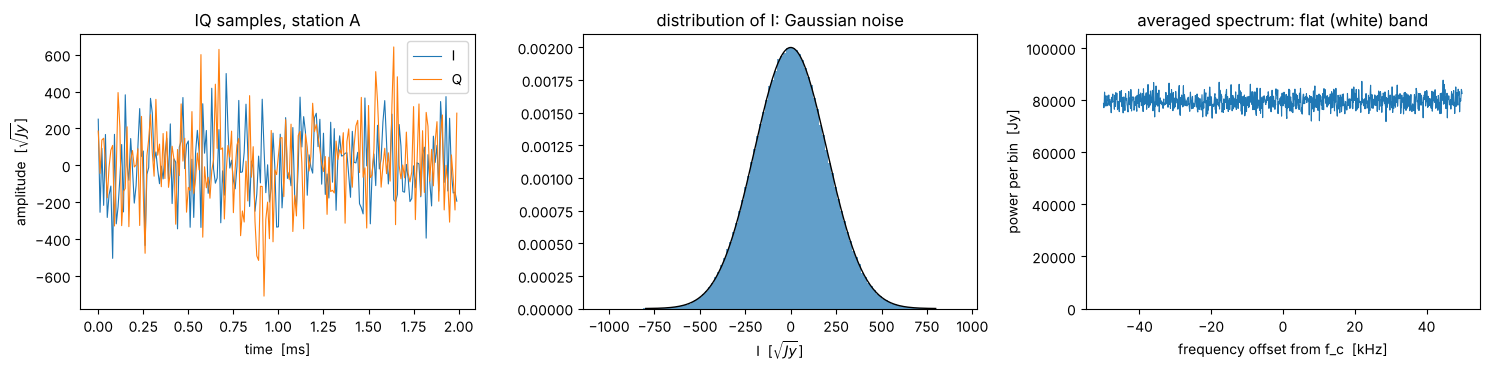

In [3]:
a = blocks["A"].data
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
t_ms = np.arange(200) / FS * 1e3
axes[0].plot(t_ms, a.real[:200], lw=0.8, label="I"); axes[0].plot(t_ms, a.imag[:200], lw=0.8, label="Q")
axes[0].set_xlabel("time  [ms]"); axes[0].set_ylabel(r"amplitude  [$\sqrt{Jy}$]"); axes[0].legend(); axes[0].set_title("IQ samples, station A")
axes[1].hist(a.real, bins=120, density=True, alpha=0.7)
sig = np.std(a.real); xx = np.linspace(-4 * sig, 4 * sig, 200)
axes[1].plot(xx, np.exp(-xx**2 / (2 * sig**2)) / (sig * np.sqrt(2 * np.pi)), "k", lw=1)
axes[1].set_title("distribution of I: Gaussian noise"); axes[1].set_xlabel(r"I  [$\sqrt{Jy}$]")
nfft = 1024
seg = a[: (a.size // nfft) * nfft].reshape(-1, nfft)
spec = np.fft.fftshift(np.mean(np.abs(np.fft.fft(seg, axis=1)) ** 2, axis=0)) / nfft
f_khz = np.fft.fftshift(np.fft.fftfreq(nfft, 1 / FS)) / 1e3
axes[2].plot(f_khz, spec, lw=0.8); axes[2].set_ylim(0, spec.max() * 1.2)
axes[2].set_xlabel("frequency offset from f_c  [kHz]"); axes[2].set_ylabel("power per bin  [Jy]")
axes[2].set_title("averaged spectrum: flat (white) band")
fig.tight_layout(); plt.show()

## 3. Raw fringes: the product without correction

Without delay tracking and fringe stopping the product $x_A x_B^*$ turns with the phase $2\pi f_c\tau_B(t)$: the Earth's rotation changes the geometric delay, the **fringe** runs through. Here on a 300 m east–west baseline (fringe period about 10 s at transit), once without receiver noise – the pure geometry – and once with noise, where the fringe disappears in short averages.

predicted fringe rate at transit: 78.5 mHz (period 12.7 s)


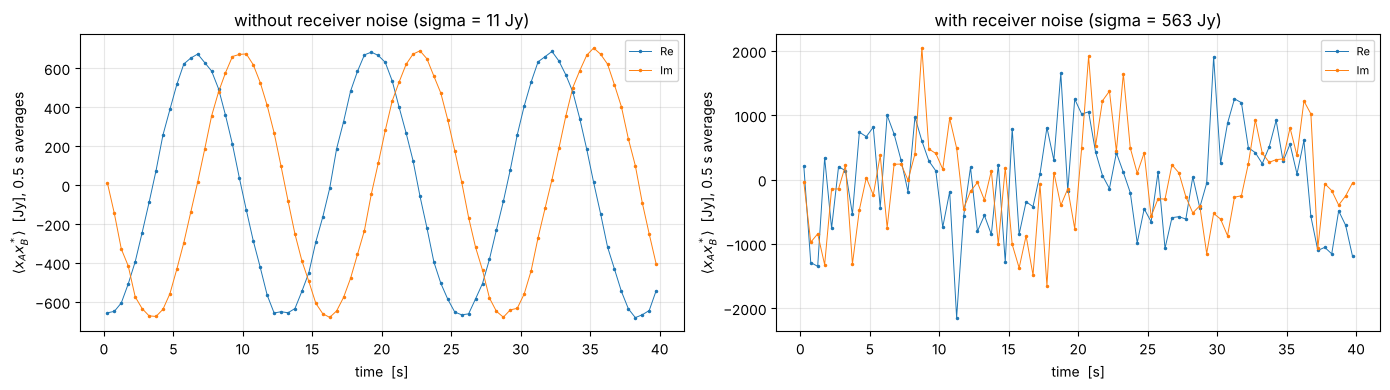

In [4]:
arr300 = ew_array(300.0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, noise in zip(axes, (False, True)):
    sim3 = IQSimulator(cyga, arr300, sample_rate_sps=2.0e4, seed=5, receiver_noise=noise)
    bl3 = sim3.simulate(40.0, lha0_deg=0.0)
    raw = measure_visibilities(bl3, sim3, 0.5, correct=False)["A-B"]
    ax.plot(raw["t_s"], raw["vis"].real, ".-", ms=3, lw=0.7, label="Re")
    ax.plot(raw["t_s"], raw["vis"].imag, ".-", ms=3, lw=0.7, label="Im")
    ax.set_xlabel("time  [s]"); ax.set_ylabel(r"$\langle x_A x_B^*\rangle$  [Jy], 0.5 s averages")
    ax.set_title(("without" if not noise else "with") + f" receiver noise (sigma = {raw['sigma']:.0f} Jy)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fr = np.gradient(sim3.phase_centre_delay_s(1, np.array([0.0, 1.0])))[0] * sim3.fc
print(f"predicted fringe rate at transit: {abs(fr) * 1e3:.1f} mHz (period {1 / abs(fr):.1f} s)")
fig.tight_layout(); plt.show()

## 4. Variable baseline: measured against the model

For a set of east–west baselines the streams are simulated, delay-tracked and fringe-stopped with the model delay of the phase centre, and correlated over 20 s. The measured visibilities follow the analytic curve of the sky model within the expected noise – the check that signal simulation, geometry and sky model are consistent. (Compare notebook 02, *choice of the baseline length*.)

b =     20 m   measured       1561.2+33.1j   model        1537.5-2.4j   sigma  56.3 Jy


b =     50 m   measured        1445.6-0.4j   model        1442.3-4.9j   sigma  56.3 Jy


b =    100 m   measured       1052.7-43.5j   model        1124.4-2.5j   sigma  56.3 Jy


b =    150 m   measured        695.1+10.2j   model        665.7+11.9j   sigma  56.3 Jy


b =    200 m   measured          6.9-19.2j   model        154.4+37.9j   sigma  56.3 Jy


b =    300 m   measured      -677.8+152.8j   model      -674.3+102.6j   sigma  56.3 Jy


... (2 outputs left out)

b =   1000 m   measured      -130.4+152.8j   model        -83.1+34.0j   sigma  56.3 Jy


b =   2000 m   measured         71.3-89.6j   model         21.7-22.9j   sigma  56.3 Jy


b =   5000 m   measured        55.2-131.9j   model       -12.8-100.2j   sigma  56.3 Jy


b =  11500 m   measured          -7.8-0.4j   model        -13.3+13.1j   sigma  56.3 Jy


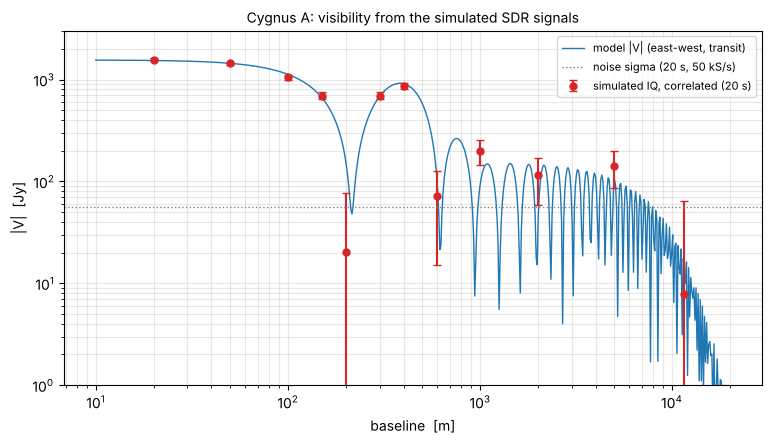

In [5]:
lam = C_LIGHT / sim.fc
baselines = [20, 50, 100, 150, 200, 300, 400, 600, 1000, 2000, 5000, 11500]
meas = []
for b_m in baselines:
    s_b = IQSimulator(cyga, ew_array(float(b_m)), sample_rate_sps=5.0e4, seed=11 + b_m)
    bl_b = s_b.simulate(20.0, lha0_deg=0.0)
    r = measure_visibilities(bl_b, s_b, 20.0)["A-B"]
    exp = s_b.expected_visibility(0, 1, r["uvw"][:, 0], r["uvw"][:, 1])[0]
    meas.append((b_m, r["vis"][0], exp, r["sigma"]))
    print(f"b = {b_m:6d} m   measured {r['vis'][0]:>18.1f}   model {exp:>18.1f}   sigma {r['sigma']:5.1f} Jy")
bb = np.logspace(1, np.log10(2e4), 600)
model_curve = np.abs(cyga.visibility(bb / lam, 0.0))
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.loglog(bb, model_curve, color="C0", lw=1, label="model |V| (east-west, transit)")
m_abs = np.array([abs(m[1]) for m in meas]); sg = np.array([m[3] for m in meas])
ax.errorbar([m[0] for m in meas], m_abs, yerr=sg, fmt="o", color="C3", ms=5, capsize=3,
            label="simulated IQ, correlated (20 s)")
ax.axhline(sg[0], color="grey", ls=":", lw=1, label="noise sigma (20 s, 50 kS/s)")
ax.set_xlabel("baseline  [m]"); ax.set_ylabel("|V|  [Jy]"); ax.set_ylim(1, 3000)
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Cygnus A: visibility from the simulated SDR signals", fontsize=10)
plt.show()

## 5. Clock errors: the frequency reference of each station

With independent stations each LO has its own frequency error $\Delta f$. After fringe stopping with the geometric model the visibility still turns at $\Delta f$; averaging over $T$ reduces its amplitude by $|\mathrm{sinc}(\Delta f\,T)|$. The B210 data sheet (notebook 02, *B210 device profile*): internal TCXO ±2 ppm, GPS-locked < 1 ppb. Here station B gets the worst case of each, on 100 m with Cyg A; the receiver noise is switched off in the figure so that only the effect of the clocks remains.

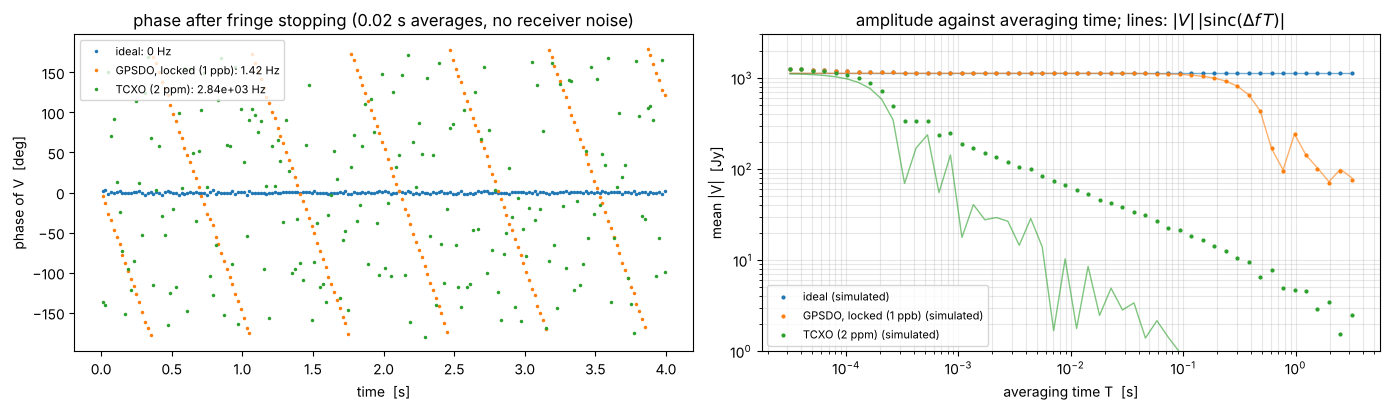

In [6]:
arr100 = ew_array(100.0)
cases = {"ideal": 0.0,
         "GPSDO, locked (1 ppb)": b210.lo_offset_hz(clock_source="gpsdo"),
         "TCXO (2 ppm)": b210.lo_offset_hz(clock_source="internal")}
# receiver noise switched off here, to show the effect of the clocks alone
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
T = np.logspace(-4.5, 0.5, 50)
for n_c, (label, df) in enumerate(cases.items()):
    s_c = IQSimulator(cyga, arr100, sample_rate_sps=5.0e4, seed=21, receiver_noise=False,
                      errors={"B": StationErrors(lo_offset_hz=df)})
    bl_c = s_c.simulate(4.0)
    r = measure_visibilities(bl_c, s_c, 0.02)["A-B"]
    axes[0].plot(r["t_s"], np.degrees(np.angle(r["vis"])), ".", ms=3, color=f"C{n_c}",
                 label=f"{label}: {df:.3g} Hz")
    amp = [np.mean(np.abs(measure_visibilities(bl_c, s_c, Ti)["A-B"]["vis"])) for Ti in T]
    axes[1].loglog(T, amp, ".", ms=4, color=f"C{n_c}", label=f"{label} (simulated)")
    v0 = abs(s_c.expected_visibility(0, 1, *r["uvw"][0, :2]))
    axes[1].loglog(T, v0 * np.maximum(np.abs(np.sinc(df * T)), 1e-6), "-", lw=1, color=f"C{n_c}", alpha=0.6)
axes[0].set_xlabel("time  [s]"); axes[0].set_ylabel("phase of V  [deg]"); axes[0].legend(fontsize=8)
axes[0].set_title("phase after fringe stopping (0.02 s averages, no receiver noise)")
axes[1].set_xlabel("averaging time T  [s]"); axes[1].set_ylabel("mean |V|  [Jy]")
axes[1].set_ylim(1, 3000)
axes[1].set_title(r"amplitude against averaging time; lines: $|V|\,|\mathrm{sinc}(\Delta f\,T)|$")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

With a GPSDO the phase turns slowly (≤ 1.4 Hz at 1420 MHz, the data-sheet accuracy as worst case): averages up to some 0.1 s are coherent, longer ones lose amplitude unless the correlator solves the fringe rate. With the free TCXO the phase turns kilohertz-fast: the visibility is gone in any practical average – the green points for longer $T$ only follow the self-noise of the sky signal, which falls as $1/\sqrt{T}$. If the offset is known – e.g. from a fringe-rate search – it can be removed:

In [7]:
df = cases["TCXO (2 ppm)"]
s_t = IQSimulator(cyga, arr100, sample_rate_sps=5.0e4, seed=22, errors={"B": StationErrors(lo_offset_hz=df)})
bl_t = s_t.simulate(4.0)
for label, lo in (("uncorrected", {}), ("LO offset removed", {"B": df})):
    r = measure_visibilities(bl_t, s_t, 4.0, lo_offsets_hz=lo)["A-B"]
    print(f"{label:<20s} V = {r['vis'][0]:>16.1f} Jy   (model {s_t.expected_visibility(0, 1, *r['uvw'][0, :2]):.1f}, sigma {r['sigma']:.1f})")

uncorrected          V =     -157.4-81.8j Jy   (model 1124.3-2.5j, sigma 126.0)
LO offset removed    V =     1069.5+43.9j Jy   (model 1124.3-2.5j, sigma 126.0)


## 6. Quantisation

The B210 digitises with 12 bits and delivers 16-bit (sc16) or 8-bit (sc8) samples. Coarser quantisation – as used in large VLBI systems with 1 or 2 bits to save data rate – reduces the measured correlation: for weak signals by $2/\pi \approx 0.64$ at 1 bit (Van Vleck), to about 0.88 at 2 bits and 0.96 at 3 bits with optimum thresholds, practically nothing from 4 bits on. The ratio of the correlation coefficient after and before quantisation:

In [8]:
s_q = IQSimulator(cyga, ew_array(50.0), sample_rate_sps=1.0e5, seed=31)
bl_q = s_q.simulate(10.0)
corr0 = measure_visibilities(bl_q, s_q, 10.0)["A-B"]
xa = bl_q["A"].data
from interferosim.signal import correct_geometry
xb = correct_geometry(bl_q["B"].data, lambda t: s_q.phase_centre_delay_s(1, t), s_q.fs, s_q.fc)
def rho(a, b):
    return abs(np.mean(a * np.conj(b))) / np.sqrt(np.mean(np.abs(a) ** 2) * np.mean(np.abs(b) ** 2))
r0 = rho(xa, xb)
print(f"correlation coefficient unquantised: {r0:.4f}")
print(f"{'bits':>4s} {'rho_q / rho':>12s}   (1 bit theory 2/pi = {2 / np.pi:.3f})")
for bits in (1, 2, 3, 4, 8, 12):
    rq = rho(quantize(xa, bits), quantize(xb, bits))
    print(f"{bits:4d} {rq / r0:12.3f}")

correlation coefficient unquantised: 0.0185
bits  rho_q / rho   (1 bit theory 2/pi = 0.637)
   1        0.650
   2        0.907


   3        0.980
   4        0.991
   8        1.001
  12        1.000


## 7. Writing the streams

`IQBlock.save_sigmf()` writes a block in the SigMF format (`.sigmf-data` complex float32, `.sigmf-meta` JSON) – the same format real B210 recordings can be stored in, so the correlator of notebook 05 can read simulated and measured data alike. The output folder `notebooks/sim_output/` is not under version control.

In [9]:
out_dir = Path("sim_output")
for name, blk in blocks.items():
    meta = blk.save_sigmf(out_dir / f"cyga_100m_{name}")
    data = meta.with_suffix(".sigmf-data")
    print(f"{data.name}: {data.stat().st_size / 1e6:.1f} MB,  {meta.name}")

cyga_100m_A.sigmf-data: 8.0 MB,  cyga_100m_A.sigmf-meta
cyga_100m_B.sigmf-data: 8.0 MB,  cyga_100m_B.sigmf-meta


## 8. Selector

Choose sky, array and baseline, duration, sample rate and frequency reference, then press *Run Interact*. The result shows the power of each station, the measured visibility against the model and the phase of the visibility over time. With a frequency reference other than *ideal* every station gets random errors within the data-sheet limits; stations closer than 100 m on one receiver (two horns on one B210) share LO and clock, so their errors cancel. (The selector needs a running kernel; long runs at high sample rates take a while.)

In [10]:
import ipywidgets as widgets
from IPython.display import display

SKY_CHOICES = {p.stem: p for p in sorted((CFG / "skies").glob("*.json"))
               if SkyModel.from_json(p).center.ra_deg is not None}
ARRAYS = {"east-west, length below": None,
          "AAS6 stations (11.1 km)": Array.from_toml(CFG / "sites" / "aas6_sim_stations.toml"),
          "two horns 10 m": Array.from_toml(CFG / "sites" / "two_horns_10m.toml")}

def run(sky_name, array_name, baseline_m, duration_s, fs_ksps, clock, noise, lha0_deg):
    sky = SkyModel.from_json(SKY_CHOICES[sky_name])
    arr = ARRAYS[array_name] or ew_array(baseline_m)
    errs = {}
    if clock != "ideal":
        rng = np.random.default_rng(7)
        # stations close together on ONE receiver (e.g. two horns on the two channels of a
        # B210) share LO and clock: identical errors cancel in the correlation
        shared = (arr.receiver.rx_channels >= len(arr) and arr.baseline_lengths_m().max() < 100.0)
        if shared:
            e = StationErrors.from_receiver(arr.receiver, rng, clock_source=clock)
            errs = {s.name: e for s in arr.stations}
        else:
            errs = {s.name: StationErrors.from_receiver(arr.receiver, rng, clock_source=clock)
                    for s in arr.stations}
    s = IQSimulator(sky, arr, sample_rate_sps=fs_ksps * 1e3, errors=errs, receiver_noise=noise, seed=1)
    bl = s.simulate(duration_s, lha0_deg=lha0_deg)
    print(f"{sky_name} on {arr.name or array_name}: baseline {arr.baseline_lengths_m()[0]:,.1f} m, "
          f"elevation {bl[arr.stations[0].name].meta['elevation_start_deg']:.1f} deg")
    for k, st in enumerate(arr.stations):
        print(f"  station {st.name}: power {np.mean(np.abs(bl[st.name].data) ** 2):,.0f} Jy, "
              f"LO offset {bl[st.name].meta['lo_offset_hz']:+.3g} Hz")
    tot = measure_visibilities(bl, s, duration_s, lha0_deg)
    seg = measure_visibilities(bl, s, max(duration_s / 40, 1 / s.fs), lha0_deg)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for name, r in tot.items():
        exp = s.expected_visibility(r["i"], r["j"], r["uvw"][:, 0], r["uvw"][:, 1])[0]
        print(f"  {name}: measured {r['vis'][0]:.1f} Jy, model {exp:.1f} Jy, sigma {r['sigma']:.1f} Jy")
        ax.plot(seg[name]["t_s"], np.degrees(np.angle(seg[name]["vis"])), ".", ms=4, label=name)
    ax.set_xlabel("time  [s]"); ax.set_ylabel("phase of V  [deg]"); ax.set_ylim(-190, 190)
    ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.show()

display(widgets.interactive(
    run, {"manual": True},
    sky_name=widgets.Dropdown(options=list(SKY_CHOICES), value="cyg_a", description="sky"),
    array_name=widgets.Dropdown(options=list(ARRAYS), description="array"),
    baseline_m=widgets.FloatLogSlider(value=100, base=10, min=1, max=4.3, description="baseline [m]"),
    duration_s=widgets.FloatSlider(value=5, min=1, max=60, step=1, description="duration [s]"),
    fs_ksps=widgets.Dropdown(options=[20, 50, 100, 200, 500], value=50, description="fs [kS/s]"),
    clock=widgets.Dropdown(options=["ideal", "gpsdo", "gpsdo_unlocked", "internal"], description="reference"),
    noise=widgets.Checkbox(value=True, description="receiver noise"),
    lha0_deg=widgets.FloatSlider(value=0, min=-90, max=90, step=5, description="hour angle [deg]"),
))

interactive(children=(Dropdown(description='sky', index=2, options=('aas6_demo', 'cas_a', 'cyg_a', 'orion_a', …